### PDAC and neural invasion - subregions of each region and the nerve microenvironment (mp_pdac03)

**Paper**: Chen MM, Gao Q, Ning H, Chen K, Gao Y, Yu M, Liu CQ, Zhou W, Pan J, Wei L, Dou W, Zhang D, Zhu L, Zhang Q, Chen R, Zhang Z. *Integrated single-cell and spatial transcriptomics uncover distinct cellular subtypes involved in neural invasion in pancreatic cancer.* Cancer Cell. 2025 Sep 8;43(9):1656-1676.e10. doi: [10.1016/j.ccell.2025.06.020](https://doi.org/10.1016/j.ccell.2025.06.020). PMID: 40680743.

Code: [github.com/PDAC-zhanglab/PDAC](https://github.com/PDAC-zhanglab/PDAC) (R figure scripts; copy in pdac/data/github_PDAC-zhanglab) - Data: GEO SuperSeries [GSE278694](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278694) = [GSE278687](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278687) (Visium, 21 sections) + [GSE278688](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278688) (scRNA) + [GSE278689](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278689) (FFPE snRNA) + GSE300435 (scTCR); raw reads GSA HRA008568.

Part A (as **mp_heart_dvlp03**): for each region of **mp_pdac01**, the spots are clustered on **gene expression** (own UMAP, ComBat by section, the 17,368 genes of the three panels) to find **subregions**, mapped on the tissue and scored on the sc/sn reference.

Part B (new; the paper's Figures 2L, 4A, 4B, 5K, 6A): **nerve spots** (Schwann share + nerve markers), **invaded / non-invaded** nerves (malignant share in and next to the nerve), and the **juxta-neural** (rings 1-2, ~200 um) and **peri-neural** (rings 3-5) microenvironment.

#### Libs: **src/libs**

- **single_cell_lib**
  - Class **SingleCell**: generic Scanpy, Squidpy, cell2location and LIANA methods
  - **DEFAULT_PARAMS**
- **single_cell_pdac_lib** (new)
  - Class **SingleCellPDAC(SingleCell)**: PDAC methods (sections, NI status and platforms, re-derived subclusters, RCTD / cell2location abundances, regions named after the paper's niches, sections as replicates for high vs low NI, nerve spots / invasion / rings)
  - **PDAC_PARAMS**, **PDAC_SUBCLUSTERS** (marker sets of the paper's subclusters), **PDAC_GENES** (26 PDAC / NI genes), **PDAC_NI_GENES**, **PDAC_NERVE_GENES**, **PAPER_NICHES**, **PDAC_FILES** (one file registry per notebook: 'pdac01' ... 'pdac04')

**Programs: src/programs**: pdac_build_h5ad.py (GEO -> h5ad), pdac_reference_subclusters.py (subclusters), run_rctd_pdac.R (RCTD), run_c2l_pdac.py (cell2location, GPU).

| section | content |
|---|---|
| 1 | spots, regions, expression |
| 2 | region signatures (table region); heatmap; maps |
| 3 | subclustering each region (own UMAP; batch = section) |
| 4 | gene sets of each subregion (partition) |
| 5 | subregion table and diagnostics; maps |
| 6 | subregion signatures on the reference |
| 7 | B1 - nerve spots and bundles; invaded vs non-invaded |
| 8 | B2 - Figure 4B: niches by ring around invaded / non-invaded nerves |
| 9 | B3 - Figure 4A: cell types of the juxta-neural spots, invaded vs non-invaded |
| 10 | B4 - Figure 2L: malignant subtypes by ring; Figure 5K: Schwann subsets in invaded vs non-invaded nerves |
| 11 | B5 - Figure 6A: Schwann subsets by distance to the malignant niches |
| 12 | tables |

Figures and tables have the prefix **pdac03_**.

### Critique of the analysis and how it is handled

1. **Nerves are inferred, not annotated.** The paper selected nerve spots by deconvolution **and** the H&E (object 'spatial_Nerve_manual' in the authors' code) and called invasion from the H&E. Here: Schwann share >= **nerve_min_schwann_share** (0.10) and nerve-marker z >= **nerve_min_marker_z** (1.0), bundles of >= 3 connected spots; **invaded** = malignant share (D02-D09) >= 0.20 over the bundle and its first ring. A manual table **pdac/data/pdac_nerve_annotation.tsv** (section, barcode, nerve, invaded) overrides the calls when present; check the calls on the H&E (section 7 figures).
2. **Rings are graph distances** on the hexagonal Visium lattice (1 ring = 100 um centre to centre), per section; a spot belongs to its nearest bundle.
3. **Spots are not independent**: the Wilcoxon p-values of section 9 are over spots (as the paper's Figure 4A) and optimistic; rank by effect size.
4. **Subregions** use the shared genes and ComBat by section; single-section subregions are flagged (**section_min_frac**).

## Loading packages

In [1]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import gc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42          # editable text in PDFs
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 90}   # inline display only; files are saved at 300 dpi
import plotly.io as pio
pio.renderers.default = "notebook_connected"

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_pdac_lib import (SingleCellPDAC, PDAC_PARAMS, PDAC_SUBCLUSTERS, PDAC_GENES, PDAC_NI_GENES,
                                       PDAC_NERVE_GENES, PAPER_NICHES, PDAC_FILES)
from libs.single_cell_lib import cmap_byr, cmap_lbwr
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import create_dir

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 200)
print({p: version(p) for p in ['scanpy', 'anndata', 'plotly']})

{'scanpy': '1.12.4', 'anndata': '0.13.4', 'plotly': '7.1.0'}


## Parameters

In [2]:
force=False       # True: recompute every table and redraw every figure (after changing parameters or inputs)
verbose=True

apply_figure_style()
scp = SingleCellPDAC(ROOT0, analysis='pdac03')
scp.set_params(subregion_skip=tuple(scp.unassigned_regions()))     # spots without deconvolution are not subclustered
root_data, root_figure, root_result = scp.root_data, scp.root_figure, scp.root_result
print(scp)
print({k: scp.params[k] for k in ['nerve_min_schwann_share', 'nerve_min_marker_z', 'nerve_min_size', 'nerve_invaded_min_malignant', 'nerve_n_rings']})
scp.calc_df_files()

SingleCellPDAC(project='pdac', adata=None, symbol_col='symbol', sample_col='section')
{'nerve_min_schwann_share': 0.1, 'nerve_min_marker_z': 1.0, 'nerve_min_size': 3, 'nerve_invaded_min_malignant': 0.2, 'nerve_n_rings': 5}
Out[2]: 
                       key  ... exists
0                   visium  ...   True
1                reference  ...   True
2                 sections  ...   True
3               visium_raw  ...   True
4                  geo_dir  ...   True
5              geo_samples  ...   True
6                   sc_dir  ...   True
7                   sn_dir  ...   True
8               st_tar_dir  ...   True
9        subcluster_labels  ...   True
10                rctd_dir  ...   True
11            rctd_weights  ...   True
12             c2l_ref_dir  ...   True
13             c2l_map_dir  ...   True
14                 c2l_map  ...  False
15              signatures  ...  False
16           region_labels  ...   True
17           region_niches  ...   True
18             region_info 

,key,root,name,path,exists
0,visium,data,pdac_visium_21sections.h5ad,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_visium_21sections.h5ad,True
1,reference,data,pdac_sc_sn_reference.h5ad,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_sc_sn_reference.h5ad,True
2,sections,data,pdac_sections.tsv,/home/flavio/uv/cell_cell_communication/pdac/data/pdac_sections.tsv,True
3,visium_raw,data,visium,/home/flavio/uv/cell_cell_communication/pdac/data/visium,True
4,geo_dir,data,geo,/home/flavio/uv/cell_cell_communication/pdac/data/geo,True
5,geo_samples,data,geo/GSE278694_samples_soft.txt,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278694_samples_soft.txt,True
6,sc_dir,data,geo/GSE278688,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278688,True
7,sn_dir,data,geo/GSE278689,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278689,True
8,st_tar_dir,data,geo/GSE278687/raw,/home/flavio/uv/cell_cell_communication/pdac/data/geo/GSE278687/raw,True
9,subcluster_labels,result,pdac01_reference_subclusters.tsv,/home/flavio/uv/cell_cell_communication/pdac/results/pdac01_reference_subclusters.tsv,True


### 1. Spots, regions and expression

In [3]:
df_regions = scp.read_tsv('region_labels', verbose=verbose)
source = df_regions['abundance_source'].iloc[0]
adata_vis = scp.read_h5ad('visium', set_self=False, verbose=verbose)
adata_vis = scp.remove_mt_genes(adata_vis)
if source == 'c2l':
    a_map = scp.read_h5ad_slots('c2l_map', skip=('layers',))
    adata_vis.obsm['q05_cell_abundance_w_sf'] = pd.DataFrame(a_map.obsm['q05_cell_abundance_w_sf'], index=a_map.obs_names).loc[adata_vis.obs_names]
    adata_vis.uns['mod'] = a_map.uns['mod']; del a_map
d = df_regions.set_index('barcode').loc[adata_vis.obs_names]
for c in ('region_cluster', 'region_label', 'region_name', 'niche'):
    adata_vis.obs[c] = pd.Categorical(d[c].astype(str).values)
names = dict(zip(d.region_label.astype(str), d.region_name.astype(str)))
df_abund = scp.get_abundance(adata_vis, source=source)
df_share = scp.shares(df_abund)
df_region_info = scp.read_region_info(source=source)
adata_expr = scp.prepare_expression(adata_vis)
sections_rep = scp.representative_sections()
print(adata_expr)
adata_expr.obs['region_label'].value_counts().sort_index().to_frame('n_spots').T

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac01_region_labels.tsv (81,846 rows)
Reading /home/flavio/uv/cell_cell_communication/pdac/data/pdac_visium_21sections.h5ad
AnnData object with n_obs × n_vars = 81846 × 17368
    obs: 'in_tissue', 'array_row', 'array_col', 'barcode', 'section', 'patient', 'ni_status', 'technique', 'gsm', 'region_cluster', 'region_label', 'region_name', 'niche', 'rctd_ok'
    var: 'symbol', 'in_FF', 'in_FFPE', 'in_CytAssist', 'n_panels', 'in_all_panels', 'MT_gene', 'ENSEMBL'
    uns: 'dataset', 'spatial', 'log1p'
    obsm: 'spatial', 'MT'
    layers: None (.X), 'counts'
Out[3]: 
region_label   R00   R01   R02   R03  R04  ...   R23  R24   R25  R26  R27
n_spots       3802  6036  1536  1768  952  ...  1043  897  1481   91   81

[1 rows x 28 columns]


region_label,R00,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12,R13,R14,R15,R16,R17,R18,R19,R20,R21,R22,R23,R24,R25,R26,R27
n_spots,3802,6036,1536,1768,952,4511,1770,6153,1947,3286,3828,2963,4118,8033,3147,502,1425,5089,3892,2427,5839,1303,3926,1043,897,1481,91,81


In [4]:
df_depth = scp.calc_df_region_depth(adata_expr, df_abund)
df_depth.T

Out[4]: 
                         R00   R01   R02    R03  ...   R24   R25  R26  R27
median_UMIs            16886  4550  6770  11147  ...  7837  5714   42   47
median_cells_per_spot      1     1     1      1  ...     1     1    0    0

[2 rows x 28 columns]


,R00,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12,R13,R14,R15,R16,R17,R18,R19,R20,R21,R22,R23,R24,R25,R26,R27
median_UMIs,16886,4550,6770,11147,11908,4373,1266,11817,9283,16374,7378,31410,8666,4841,8514,2712,20668,947,1848,14786,6526,21696,17933,36007,7837,5714,42,47
median_cells_per_spot,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0


### 2. Region signatures (table region)

Each region vs all other spots (Wilcoxon on log1p CP10k): signature = logFC >= 1, FDR <= 0.05, detected in >= 25% of the region's spots.

In [5]:
df_rank_region, region_sig = scp.calc_df_region_signature(adata_expr, force=force, verbose=verbose)
df_region_table = scp.calc_df_region_table(adata_expr, df_rank_region, region_sig, df_abund, df_region_info, force=force, verbose=verbose)
cols = [c for c in ['region_id', 'region_name', 'n_spots', 'median_UMIs', 'n_signature_genes', 'signature_genes', 'enriched_cell_types'] if c in df_region_table]
df_region_table[cols]

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_region_rank_genes.tsv.gz (486,304 rows)
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_region_table.tsv (28 rows)
Out[5]: 
   region_id  ...                                                                     enriched_cell_types
0        R00  ...                                D01_Ductal-CFTR (x10.3), Endocrine (x2.2), Acinar (x2.1)
1        R01  ...                          F06_Fibro-MALAT1 (x2.8), Plasma (x2.5), M08_Macro-LYVE1 (x1.6)
2        R02  ...                     Stellate (x17.8), Endothelial (x2.0), F02_Progenitor-CAF-DPT (x1.9)
3        R03  ...                                            B (x14.8), CD4T (x4.9), M04_cDC-LAMP3 (x4.1)
4        R04  ...              S01_Schwann-ABCA8 (x16.3), F07_Fibro-NRP2 (x6.3), S02_Schwann-TGFBI (x6.0)
5        R05  ...                    Plasma (x7.2), F02_Progenitor-CAF-DPT (x2.2), M08_Macro-LYVE1 (x1.7)
6        R06  ...                           D0

,region_id,region_name,n_spots,median_UMIs,n_signature_genes,signature_genes,enriched_cell_types
0,R00,N11_Non-malignant-pancreas,3802,16886,490,"CFTR, FXYD2, PIGR, SLC4A4, SERPINA3, ANXA4, REG1A, SERPINA1, SPP1, SERPINA5, CFB, SLC3A1","D01_Ductal-CFTR (x10.3), Endocrine (x2.2), Acinar (x2.1)"
1,R01,N04_Plasma-enriched,6036,4550,42,"IGKC, COL3A1, IGHG1, COL1A1, COL4A2, CHST11, IGHA1, IGHG3, PIM2, C11orf96, BTG2, MZB1","F06_Fibro-MALAT1 (x2.8), Plasma (x2.5), M08_Macro-LYVE1 (x1.6)"
2,R02,N03_Peri-vascular,1536,6770,598,"TAGLN, MYL9, ACTA2, MCAM, TPM2, C11orf96, CALD1, ADIRF, MYLK, A2M, LMOD1, RHOB","Stellate (x17.8), Endothelial (x2.0), F02_Progenitor-CAF-DPT (x1.9)"
3,R03,N01_TLS,1768,11147,1482,"CCL19, LTB, CD37, CXCR4, TRAC, TRBC2, IKZF1, MS4A1, AKNA, CORO1A, TRBC1, SELL","B (x14.8), CD4T (x4.9), M04_cDC-LAMP3 (x4.1)"
4,R04,N12_Nerve,952,11908,885,"ITGB8, LGI4, S100B, VIM, NRXN1, CRYAB, CDH19, PLP1, SEMA3B, SOX10, GAP43, GPM6B","S01_Schwann-ABCA8 (x16.3), F07_Fibro-NRP2 (x6.3), S02_Schwann-TGFBI (x6.0)"
5,R05,N04_Plasma-enriched,4511,4373,133,"IGHG1, IGKC, MZB1, IGHG3, PIM2, XBP1, JCHAIN, BTG2, TXNDC5, PTGDS, TENT5C, ITM2C","Plasma (x7.2), F02_Progenitor-CAF-DPT (x2.2), M08_Macro-LYVE1 (x1.7)"
6,R06,mixed (malignant / N05_CAF-enriched),1770,1266,2,"HBA2, ZNF595","D06_Ductal-MYO1A (x5.0), Endocrine (x1.8), Endothelial (x1.8)"
7,R07,N05_CAF-enriched,6153,11817,308,"CTHRC1, FN1, POSTN, SULF1, COL5A1, COL1A1, VCAN, SPARC, THBS2, COL3A1, COL1A2, COL5A2","F01_myCAF-MMP11 (x3.2), M08_Macro-LYVE1 (x1.7), D04_Ductal-GABRP (x1.2)"
8,R08,N07-10_Malignant (Ductal-other),1947,9283,462,"S100A11, UBC, ACTB, TAGLN2, LCN2, S100A6, B2M, CTSD, SPINK1, JUP, PTGES3, EIF1","Ductal-other (x7.3), F05_dCAF-MKI67 (x2.4), D07_Ductal-MKI67 (x2.1)"
9,R09,N05_CAF-enriched,3286,16374,641,"TMPRSS3, SYNE2, SMIM24, COL10A1, VCAN, GAS6, SLC12A2, LIPH, TOB1, SHROOM3, MUC6, WNT10A","F01_myCAF-MMP11 (x3.0), D08_Ductal-CEACAM5 (x2.4), Ductal-other (x2.3)"


In [6]:
fig = scp.plotly_region_signature_heatmap(adata_expr, df_rank_region, n_per_region=3, fontsize_title=22, fontsize_xticks=14,
                                          fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=13, height=1100, width=1400,
                                          force=force, verbose=False)
fig.show()

In [7]:
for lib in sections_rep:
    fig = scp.plotly_region_map(adata_expr, adata_vis, lib, df_region_table=df_region_table, fontsize_title=20, fontsize_legend=12,
                                fontsize_hover=13, force=force, verbose=False)
    if lib == scp.params['library_main']:
        fig.show()

### 3. Subclustering each region (own UMAP; batch = section)

**subcluster_adaptive** per region (sections with < 10 spots in the region pooled for ComBat): 2,000 HVGs, ComBat, PCA (20), kNN (15), UMAP, Leiden over **sub_resolutions**; the highest resolution with every subregion >= **sub_min_size** spots and <= **sub_max_k** subregions.

In [8]:
subs, df_grid = scp.run_subregions(adata_expr, force=force, verbose=False)
df_grid[df_grid.chosen][['region_id', 'resolution', 'k', 'min_size']]

Out[8]: 
    region_id  resolution  k  min_size
0         R00         0.2  8        18
6         R01         0.2  6        40
12        R02         0.2  5        16
19        R03         0.3  6        29
24        R04         0.2  5        41
31        R05         0.3  6        26
40        R06         0.6  6        36
42        R07         0.2  8        66
51        R08         0.5  6       174
54        R09         0.2  5       156
60        R10         0.2  8        37
66        R11         0.2  4        42
73        R12         0.3  6        33
78        R13         0.2  6        40
84        R14         0.2  6        34
95        R15         0.8  5        64
96        R16         0.2  5       117
102       R17         0.2  6        29
108       R18         0.2  3        28
114       R19         0.2  5       282
121       R20         0.3  6        27
126       R21         0.2  6         9
133       R22         0.3  5       617
140       R23         0.4  5       106
145       R24   

,region_id,resolution,k,min_size
0,R00,0.2,8,18
6,R01,0.2,6,40
12,R02,0.2,5,16
19,R03,0.3,6,29
24,R04,0.2,5,41
31,R05,0.3,6,26
40,R06,0.6,6,36
42,R07,0.2,8,66
51,R08,0.5,6,174
54,R09,0.2,5,156


### 4. Gene sets of each subregion (partition)

In [9]:
df_gene_sets = scp.calc_df_subregion_gene_sets(adata_expr, region_sig, force=force, verbose=False)
df_set_counts = df_gene_sets.groupby(['sub_region_id', 'gene_set'], sort=False).size().unstack(fill_value=0)
df_set_counts['total'] = df_set_counts.sum(1)
n_universe = df_gene_sets.groupby('sub_region_id', sort=False).size()
assert (df_set_counts['total'] == n_universe.loc[df_set_counts.index]).all()
print(f"{len(df_set_counts)} subregions; the 4 sets partition every universe")
df_set_counts.head(12)

147 subregions; the 4 sets partition every universe
Out[9]: 
gene_set       other  region_signature  subregion_signature  not_present  total
sub_region_id                                                                  
R00_1          16625               490                  122            0  17237
R00_2          16114               490                  633            0  17237
R00_3          15644               490                 1102            1  17237
R00_4          16284               490                  463            0  17237
R00_5          15476               490                 1271            0  17237
R00_6          16542               490                    6          199  17237
R00_7          15918               490                  828            1  17237
R00_8          16502               490                  245            0  17237
R01_1          17169                42                   10            0  17221
R01_2          15070                42                 2109

gene_set,other,region_signature,subregion_signature,not_present,total
sub_region_id,,,,,
R00_1,16625,490,122,0,17237
R00_2,16114,490,633,0,17237
R00_3,15644,490,1102,1,17237
R00_4,16284,490,463,0,17237
R00_5,15476,490,1271,0,17237
R00_6,16542,490,6,199,17237
R00_7,15918,490,828,1,17237
R00_8,16502,490,245,0,17237
R01_1,17169,42,10,0,17221


### 5. Subregion table, diagnostics and maps

In [10]:
df_sub_table = scp.calc_df_subregion_table(adata_expr, df_gene_sets, df_abund, df_descriptions=None, force=force, verbose=False)
print(df_sub_table.status.str.split(';').str[0].value_counts().to_dict())
cols = ['sub_region_id', 'n_spots', 'coherence_ratio', 'depth_ratio', 'border_region', 'n_subregion_signature', 'n_not_present', 'status']
df_sub_table[[c for c in cols if c in df_sub_table]].head(15)

{'supported': 116, 'weak': 31}
Out[10]: 
   sub_region_id  ...                                                 status
0          R00_1  ...                                   weak; single-section
1          R00_2  ...                              supported; single-section
2          R00_3  ...                              supported; single-section
3          R00_4  ...                              supported; single-section
4          R00_5  ...                              supported; single-section
5          R00_6  ...                   supported; single-section; low-depth
6          R00_7  ...                              supported; single-section
7          R00_8  ...                              supported; single-section
8          R01_1  ...                                   weak; single-section
9          R01_2  ...                  supported; single-section; high-depth
10         R01_3  ...             supported; single-section; border with R13
11         R01_4  ...  supported; s

,sub_region_id,n_spots,coherence_ratio,depth_ratio,border_region,n_subregion_signature,n_not_present,status
0,R00_1,2341,1.21,0.92,R11,122,0,weak; single-section
1,R00_2,560,3.59,1.60,R11,633,0,supported; single-section
2,R00_3,289,2.28,0.68,R03,1102,1,supported; single-section
3,R00_4,250,6.20,0.89,R11,463,0,supported; single-section
4,R00_5,224,3.66,1.11,R12,1271,0,supported; single-section
5,R00_6,92,7.43,0.18,R19,6,199,supported; single-section; low-depth
6,R00_7,28,27.53,1.19,R22,828,1,supported; single-section
7,R00_8,18,34.88,1.13,R18,245,0,supported; single-section
8,R01_1,4997,1.13,0.93,R14,10,0,weak; single-section
9,R01_2,277,7.85,2.56,R00,2109,0,supported; single-section; high-depth


In [11]:
fig = scp.plotly_subregion_diagnostics(df_sub_table, fontsize_title=22, fontsize_axis=18, fontsize_ticks=16, fontsize_legend=12,
                                       fontsize_legend_title=16, fontsize_hover=13, grid_color="#555555", height=800, width=1800,
                                       force=force, verbose=False)
fig.show()

In [12]:
for lib in sections_rep:
    fig = scp.plotly_subregion_map(adata_expr, adata_vis, lib, df_sub_table=df_sub_table, fontsize_title=20, fontsize_legend=11,
                                   fontsize_legend_title=14, fontsize_hover=13, legend_ncols=3, width=1800, height=900,
                                   force=force, verbose=False)
    if lib == scp.params['library_main']:
        fig.show()

### 6. Subregion signatures on the reference

Top 25 subregion-signature genes of every **supported** subregion scored on the sc/sn reference (tissue cells, <= 3,000 per type): mean per-gene z-score of log1p(CP10k), mean per cell type.

dropped (< 25 tissue cells): ['Platelet']
reference for deconvolution: 56,632 of 141,683 tissue cells, 42 cell types
File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_subregion_ref_celltype_heatmap.png


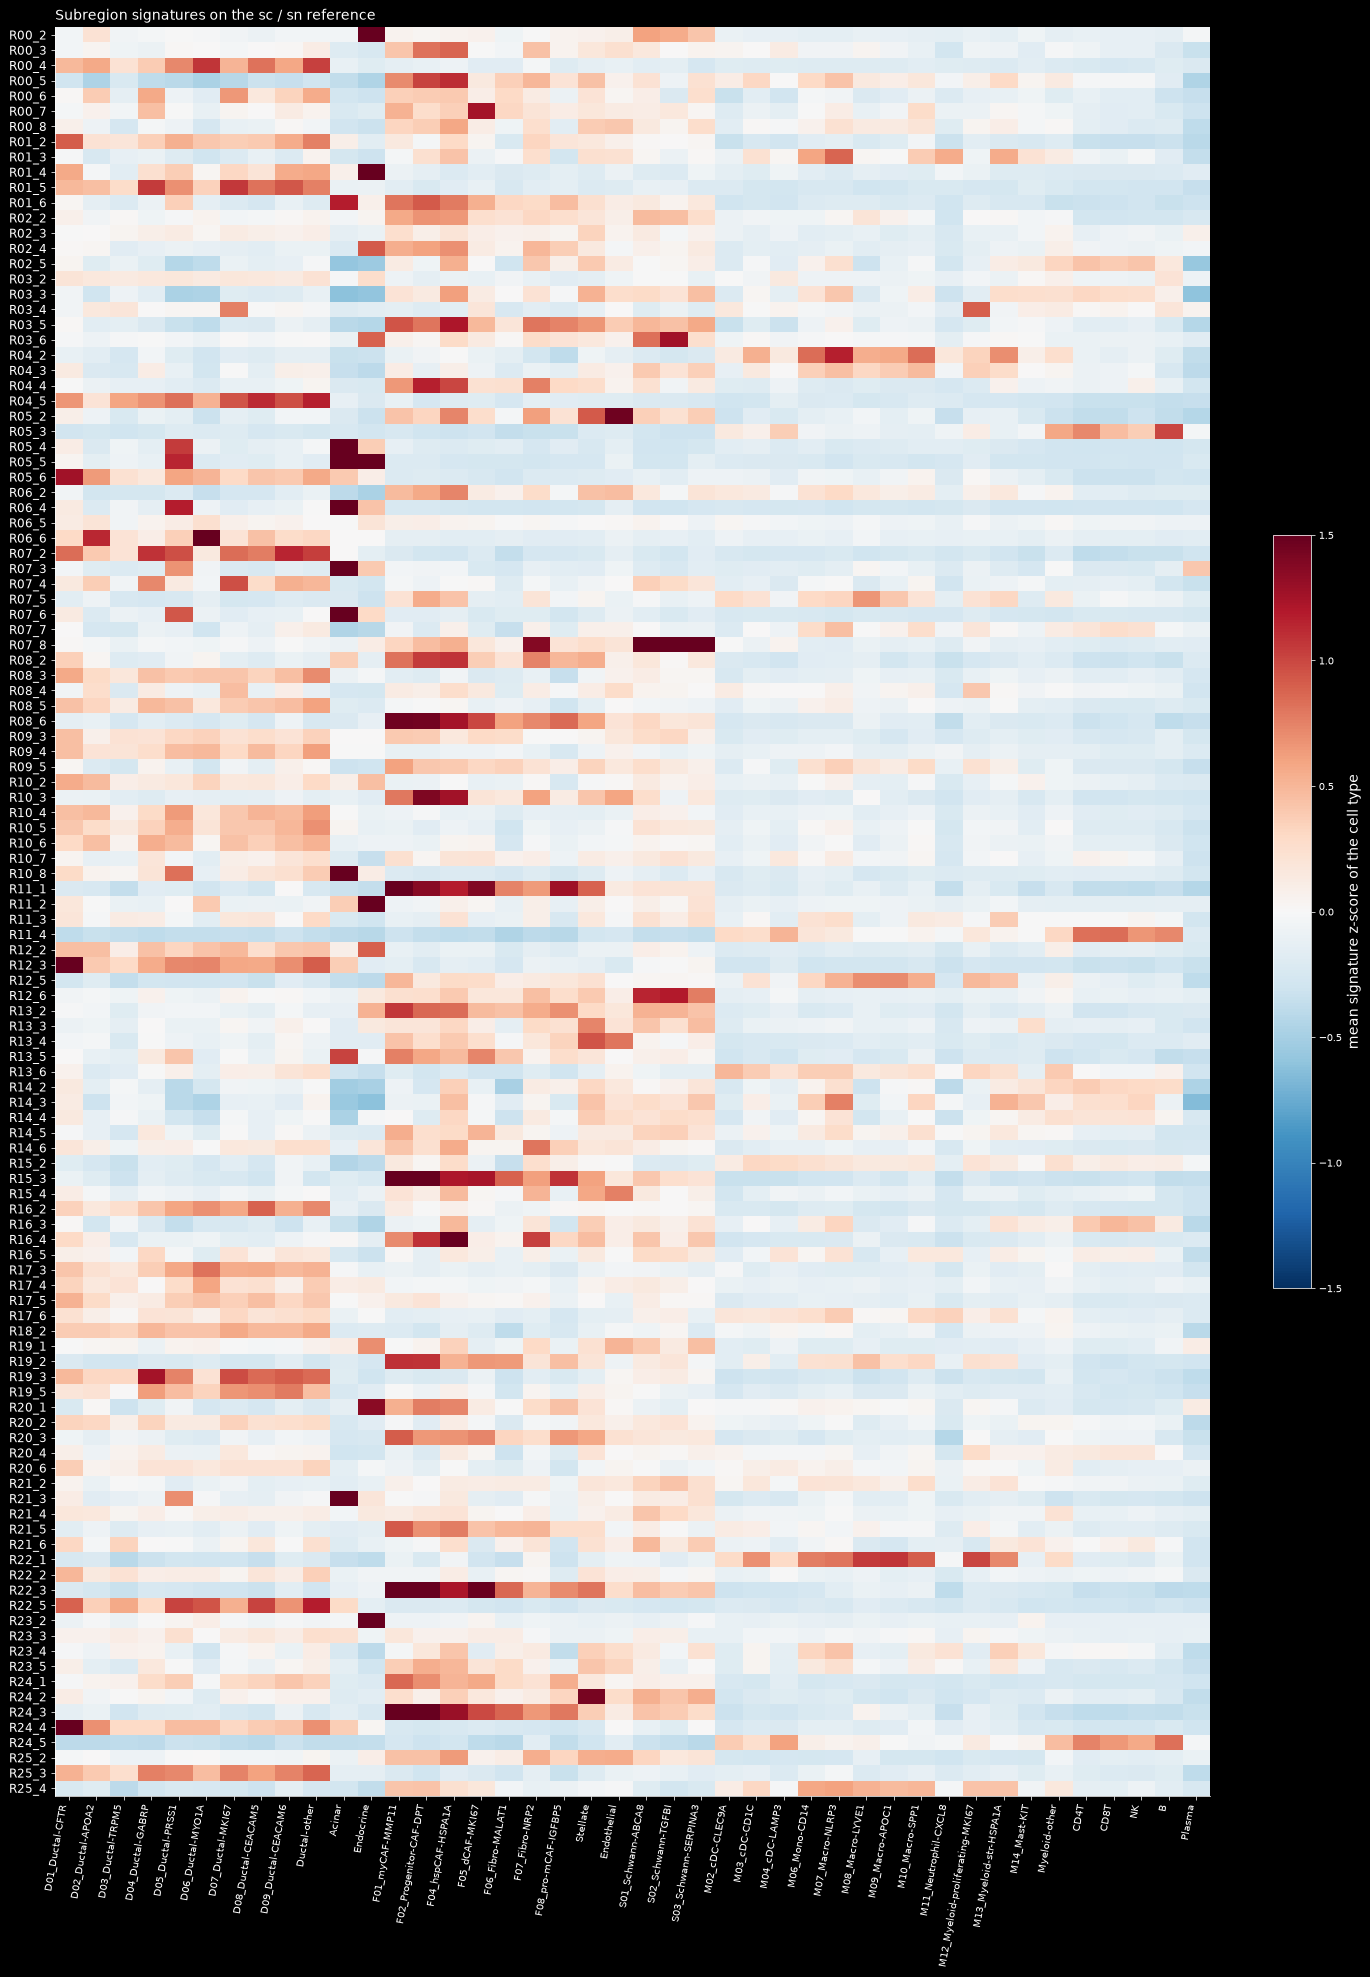

In [13]:
adata_ref = scp.read_h5ad('reference', set_self=False, backed='r')
adata_ref_dec = scp.reference_for_deconvolution(adata_ref)
adata_ref_sym = adata_ref_dec.copy()
adata_ref_sym.var_names = adata_ref_sym.var['symbol'].astype(str).values
adata_ref_sym.var_names_make_unique()
df_ref_score, df_cell_score, genes_used = scp.calc_df_subregion_ref_score(adata_ref_sym, df_gene_sets, df_sub_table, force=force, verbose=False)
fig = scp.plot_subregion_ref_heatmap(df_ref_score, figsize=(18, max(6, 0.22 * len(df_ref_score))), fname=scp.fname('fig_ref_heatmap'),
                                     force=force, verbose=verbose)
plt.show()
df_sub_table = scp.add_ref_cell_types(df_sub_table, df_ref_score, n=3, force=force, verbose=False)

### 7. B1 - Nerve spots and bundles; invaded vs non-invaded

**scp.call_nerves** (cached in **pdac03_nerve_spots.tsv**). The table lists one row per bundle; the maps show nerve spots (yellow: non-invaded, red: invaded) and the rings around them on the representative sections. Compare PA98 with the paper's Figure 1E (red: invaded, blue: non-invaded nerves on the H&E).

In [14]:
df_nerve = scp.call_nerves(adata_vis, df_abund, fname='nerve_spots', force=force, verbose=verbose)
df_bundles = scp.calc_df_nerve_table(df_nerve, fname='nerve_table', force=force, verbose=verbose)
print(f"nerve spots: {(df_nerve.nerve_id != '').sum():,}; bundles: {len(df_bundles)} "
      f"(invaded {int((df_bundles.status == 'invaded').sum())}, non-invaded {int((df_bundles.status == 'non-invaded').sum())})")
display(df_bundles.groupby(['ni_status', 'status']).agg(n_bundles=('nerve_id', 'size'), n_spots=('n_spots', 'sum')))
df_bundles.head(20)

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_nerve_spots.tsv (81,846 rows)
Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_nerve_bundles.tsv (65 rows)
nerve spots: 973; bundles: 65 (invaded 16, non-invaded 49)
Out[14]: 
      nerve_id section  n_spots  ... schwann_share  malignant_share  ni_status
0      PA03_n2    PA03        4  ...         0.536            0.119       high
1      PA03_n1    PA03        3  ...         0.273            0.271       high
2      PA03_n6    PA03        3  ...         0.250            0.232       high
3    PA05-2_n2  PA05-2       61  ...         0.291            0.083       high
4    PA05-2_n3  PA05-2       22  ...         0.222            0.037       high
5    PA05-2_n4  PA05-2        8  ...         0.246            0.392       high
6    PA05-2_n0  PA05-2        7  ...         0.177            0.518       high
7   PA05-2_n10  PA05-2        5  ...         0.212            0.399       high
8   PA05-2_n13  PA05-2    

n_bundles  n_spots
ni_status status                         
high      invaded             16      103
          non-invaded         31      754
low       non-invaded         18      116

,nerve_id,section,n_spots,status,schwann_share,malignant_share,ni_status
0,PA03_n2,PA03,4,invaded,0.536,0.119,high
1,PA03_n1,PA03,3,invaded,0.273,0.271,high
2,PA03_n6,PA03,3,invaded,0.250,0.232,high
3,PA05-2_n2,PA05-2,61,non-invaded,0.291,0.083,high
4,PA05-2_n3,PA05-2,22,non-invaded,0.222,0.037,high
5,PA05-2_n4,PA05-2,8,invaded,0.246,0.392,high
6,PA05-2_n0,PA05-2,7,invaded,0.177,0.518,high
7,PA05-2_n10,PA05-2,5,invaded,0.212,0.399,high
8,PA05-2_n13,PA05-2,3,non-invaded,0.119,0.037,high
9,PA05-2_n15,PA05-2,3,non-invaded,0.104,0.018,high


File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_nerves_on_sections.png


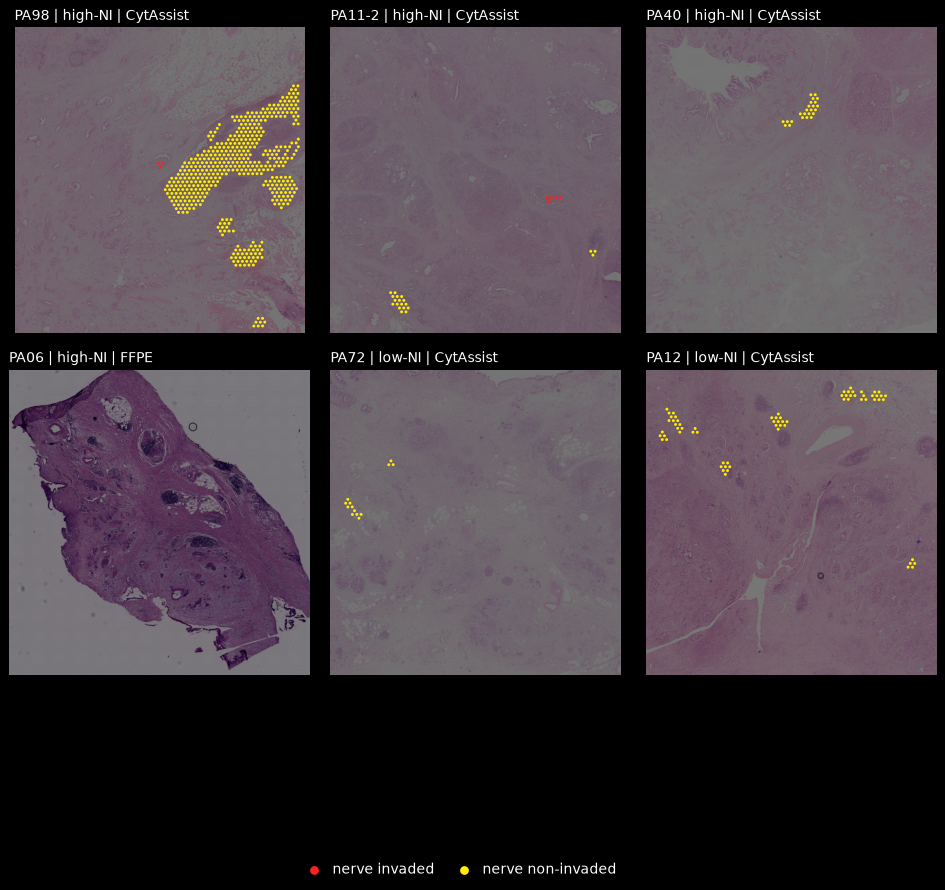

In [15]:
adata_vis.obs['nerve_call'] = np.where(adata_vis.obs.nerve_status == '', '', 'nerve ' + adata_vis.obs.nerve_status)
cz = {'nerve invaded': '#FF2020', 'nerve non-invaded': '#FFEE00'}
fig = scp.plot_regions_on_sections(adata_vis, key='nerve_call', sections=sections_rep, colors=cz, ncols=3, panel_size=4.5,
                                   legend_ncol=2, fname=scp.fname('fig_nerves'), force=force, verbose=verbose)
plt.show()

File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_nerve_rings_PA98.png


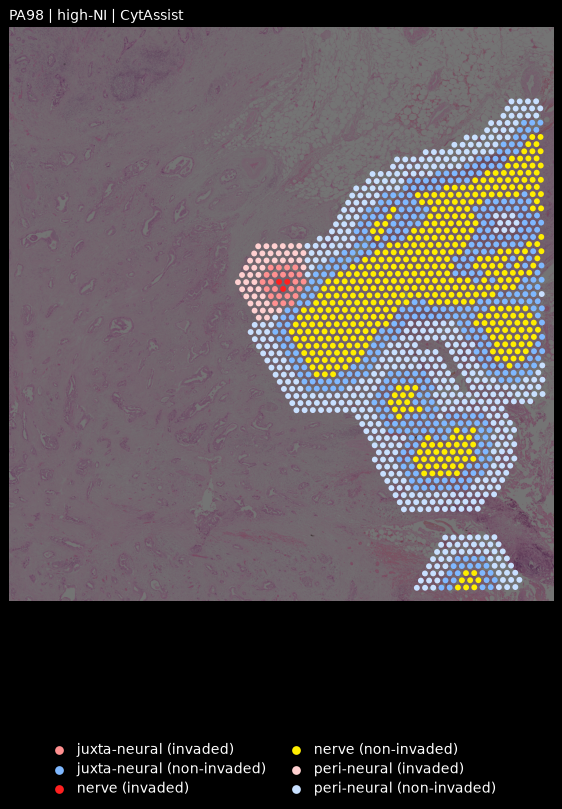

In [16]:
lib = scp.params['library_main']
z = adata_vis.obs.nerve_zone.astype(str) + np.where(adata_vis.obs.ring_status != '', ' (' + adata_vis.obs.ring_status.astype(str) + ')', '')
adata_vis.obs['nerve_zone_status'] = np.where(adata_vis.obs.nerve_zone == '', '', z)
cz = {'nerve (invaded)': '#FF2020', 'juxta-neural (invaded)': '#FF9090', 'peri-neural (invaded)': '#FFD0D0',
      'nerve (non-invaded)': '#FFEE00', 'juxta-neural (non-invaded)': '#7FB8FF', 'peri-neural (non-invaded)': '#C8E0FF'}
fig = scp.plot_regions_on_sections(adata_vis, key='nerve_zone_status', sections=[lib], colors=cz, ncols=1, panel_size=8, legend_ncol=2,
                                   fname=scp.fname('fig_nerve_rings', lib=lib), force=force, verbose=verbose)
plt.show()

### 8. B2 - Figure 4B: niches by ring around invaded / non-invaded nerves

Share of each niche among the spots of every ring (5 -> 1 = juxta, 0 = nerve), around invaded (dashed) and non-invaded nerves (solid). Paper: TLS, plasma and peri-vascular niches near non-invaded nerves; CAF / TAM / malignant niches near invaded nerves.

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_niche_by_nerve_ring.tsv (180 rows)
File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_niche_by_nerve_ring.png


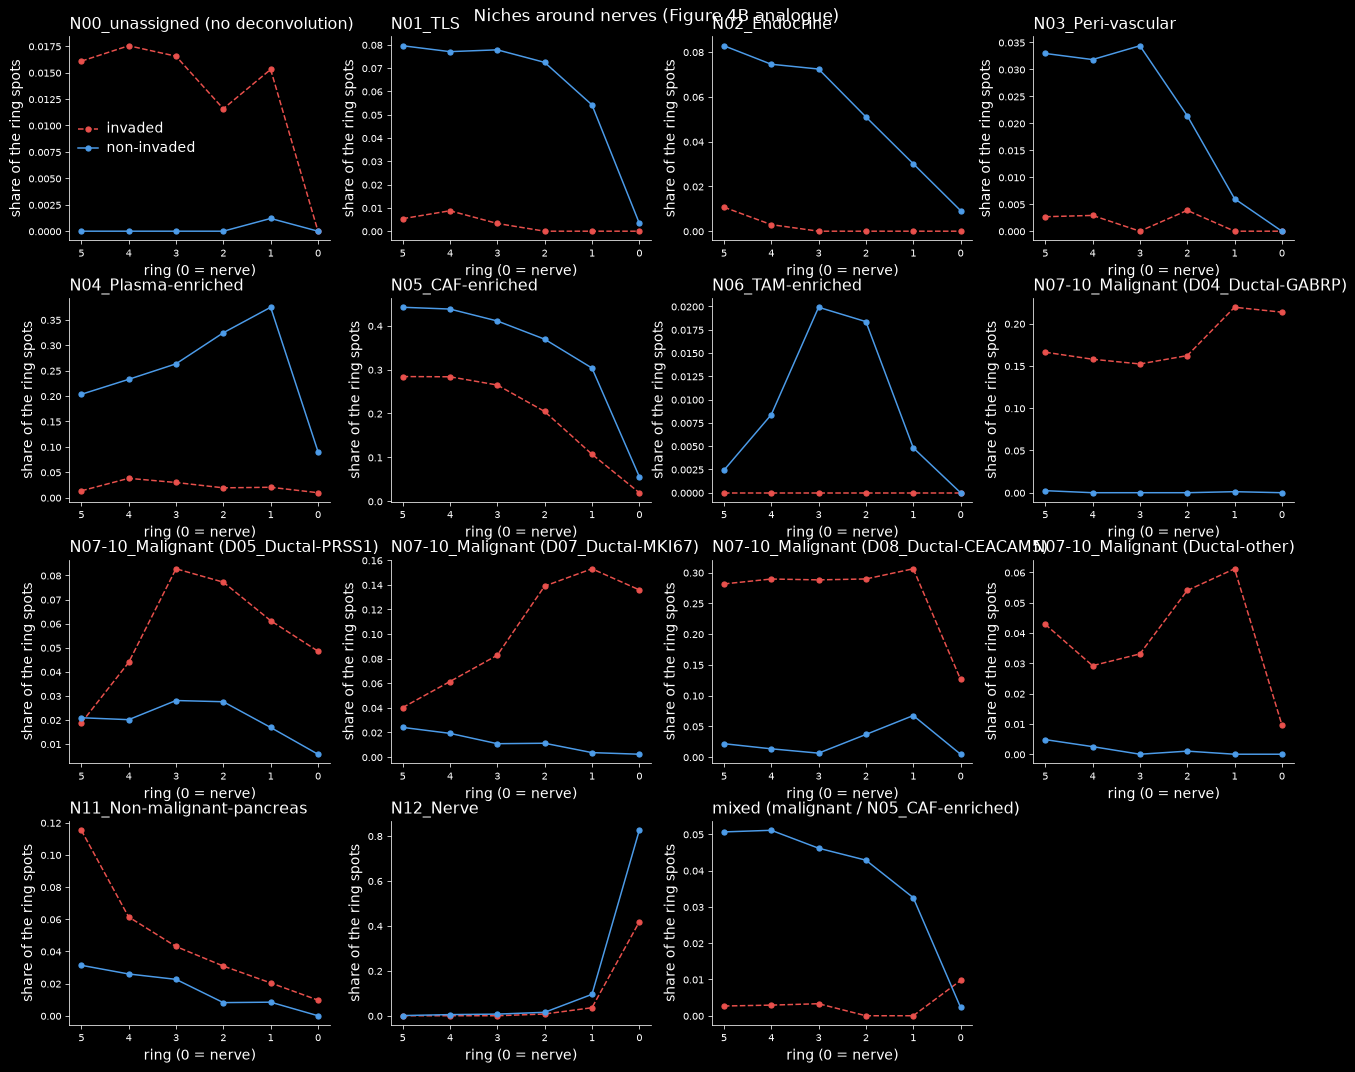

In [17]:
D_niche = pd.get_dummies(adata_vis.obs['niche'].astype(str)).astype(float)
df_ring_niche = scp.calc_df_ring_profile(adata_vis, D_niche, fname='tsv_ring_niche', force=force, verbose=verbose)
fig = scp.plot_ring_profile(df_ring_niche, sorted(D_niche.columns), ncols=4, ylabel='share of the ring spots',
                            title='Niches around nerves (Figure 4B analogue)', fname=scp.fname('fig_ring_niche'), force=force, verbose=verbose)
plt.show()

### 9. B3 - Figure 4A: cell types of the juxta-neural spots, invaded vs non-invaded

Mean share in rings 1-2 around invaded vs non-invaded nerves; two-sided Mann-Whitney over spots. Paper: around invaded nerves M07_Macro-NLRP3, myCAF (F01) and malignant cells; around non-invaded nerves TLS cells (B, Tfh), plasma cells, progenitor CAF.

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_juxtaneural_invaded_vs_noninvaded.tsv (42 rows)
{'n_invaded': 455, 'n_non_invaded': 1810}
File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_juxtaneural_invaded_vs_noninvaded.png
Out[18]: 
              cell_type     lineage  ...         p       fdr
0    D09_Ductal-CEACAM6  epithelial  ...  0.000000  0.000000
1      D04_Ductal-GABRP  epithelial  ...  0.000000  0.000000
2          Ductal-other  epithelial  ...  0.000000  0.000000
3        M10_Macro-SPP1     myeloid  ...  0.000031  0.000036
4   F08_pro-mCAF-IGFBP5     stromal  ...  0.000000  0.000000
5        F05_dCAF-MKI67     stromal  ...  0.000000  0.000000
6      D07_Ductal-MKI67  epithelial  ...  0.000000  0.000000
7      D05_Ductal-PRSS1  epithelial  ...  0.000004  0.000005
8       D01_Ductal-CFTR  epithelial  ...  0.000312  0.000336
9    D08_Ductal-CEACAM5  epithelial  ...  0.000000  0.000000
10      M09_Macro-APOC1     myeloid  ...  

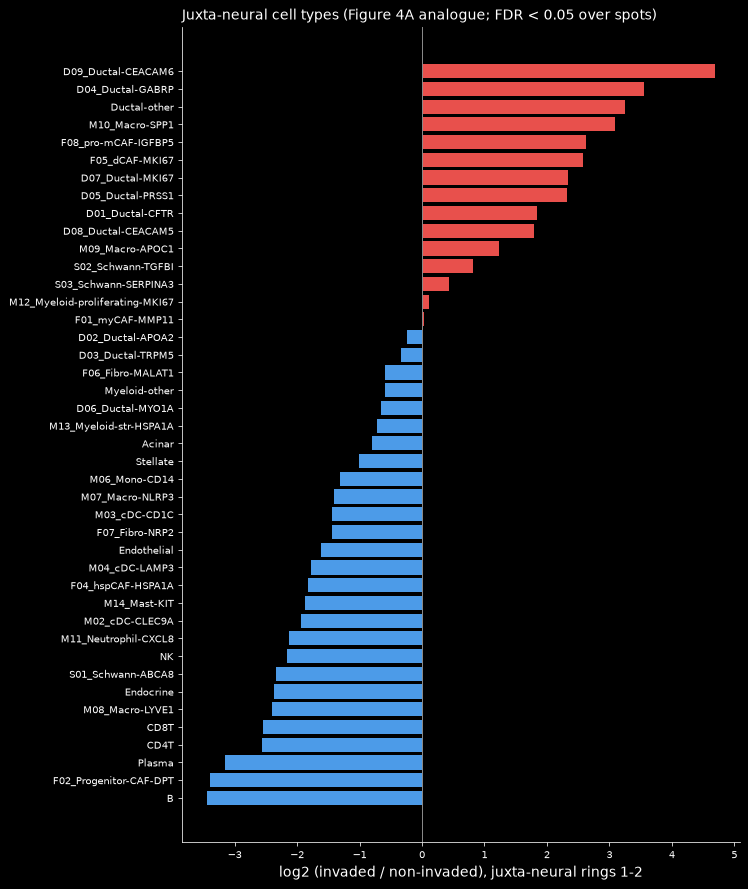

,cell_type,lineage,mean_invaded,mean_non_invaded,log2_ratio,p,fdr
0,D09_Ductal-CEACAM6,epithelial,0.074711,0.002813,4.682880,0.000000,0.000000
1,D04_Ductal-GABRP,epithelial,0.166679,0.014092,3.554815,0.000000,0.000000
2,Ductal-other,epithelial,0.065345,0.006768,3.252295,0.000000,0.000000
3,M10_Macro-SPP1,myeloid,0.010487,0.001144,3.089262,0.000031,0.000036
4,F08_pro-mCAF-IGFBP5,stromal,0.035364,0.005666,2.620615,0.000000,0.000000
5,F05_dCAF-MKI67,stromal,0.036734,0.006056,2.580856,0.000000,0.000000
6,D07_Ductal-MKI67,epithelial,0.097491,0.019243,2.334957,0.000000,0.000000
7,D05_Ductal-PRSS1,epithelial,0.028067,0.005542,2.319776,0.000004,0.000005
8,D01_Ductal-CFTR,epithelial,0.014808,0.004043,1.847365,0.000312,0.000336
9,D08_Ductal-CEACAM5,epithelial,0.098221,0.028173,1.798077,0.000000,0.000000


In [18]:
df_juxta = scp.calc_df_juxta_enrichment(adata_vis, df_share, fname='tsv_juxta', force=force, verbose=verbose)
print(df_juxta.attrs)
fig = scp.plot_juxta_enrichment(df_juxta, max_fdr=0.05, fname='fig_juxta', force=force, verbose=verbose)
plt.show()
df_juxta.head(12)

### 10. B4 - Figure 2L: malignant subtypes by ring; Figure 5K: Schwann subsets in nerves

Paper (2L): D09_Ductal-CEACAM6 and D04_Ductal-GABRP most prevalent within 1 spot of invaded nerves. Paper (5K): S03_Schwann-SERPINA3 higher in non-invaded nerve spots.

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_malignant_by_nerve_ring.tsv (96 rows)
File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_malignant_by_nerve_ring.png
Out[19]: 
             S01_Schwann-ABCA8  S02_Schwann-TGFBI  S03_Schwann-SERPINA3
invaded                  0.129              0.837                 0.034
non-invaded              0.784              0.208                 0.008


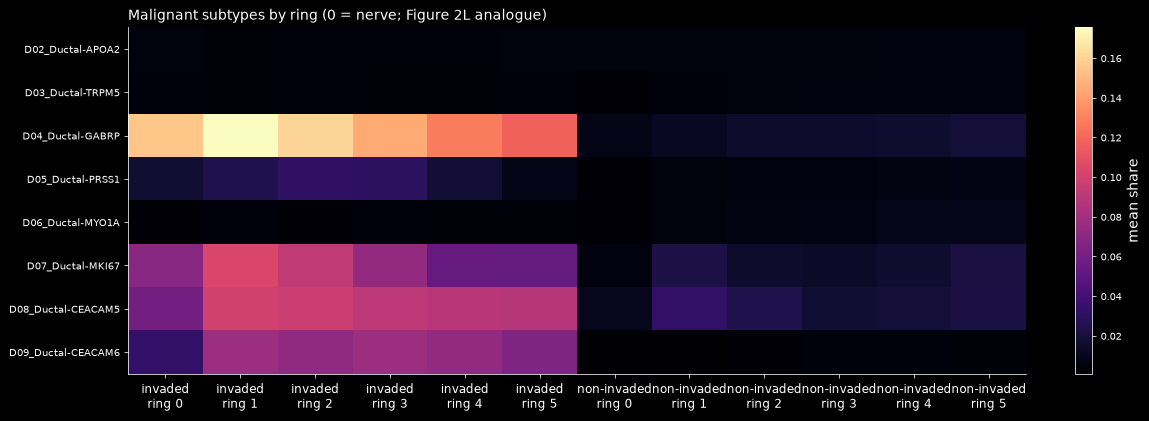

,S01_Schwann-ABCA8,S02_Schwann-TGFBI,S03_Schwann-SERPINA3
invaded,0.129,0.837,0.034
non-invaded,0.784,0.208,0.008


In [19]:
mal = [c for c in df_share.columns if c[:3] in ('D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09')]
df_ring_mal = scp.calc_df_ring_profile(adata_vis, df_share[mal], fname='tsv_ring_malignant', force=force, verbose=verbose)
fig = scp.plot_ring_heatmap(df_ring_mal, title='Malignant subtypes by ring (0 = nerve; Figure 2L analogue)',
                            fname='fig_ring_malignant', force=force, verbose=verbose)
plt.show()
schw = [c for c in df_share.columns if c.startswith('S0')]
nv = adata_vis.obs.nerve_ring.values == 0
df_s5k = df_share.loc[nv, schw].groupby(adata_vis.obs.loc[nv, 'nerve_status'].values).mean()
df_s5k.div(df_s5k.sum(1), axis=0).round(3)

### 11. B5 - Figure 6A: Schwann subsets by distance to the malignant niches

Nerve spots grouped by graph distance to the nearest malignant-niche spot ('radius 1-5', farther spots in 5); share of each Schwann subset among the Schwann cells. Paper: S02_Schwann-TGFBI increases towards the tumour (leading edge of NI).

Reading /home/flavio/uv/cell_cell_communication/pdac/results/pdac03_schwann_by_distance_to_malignant.tsv (6 rows)
File already exists: /home/flavio/uv/cell_cell_communication/pdac/figures/pdac03_schwann_by_distance_to_malignant.png
Out[20]: 
        S01_Schwann-ABCA8  S02_Schwann-TGFBI  S03_Schwann-SERPINA3  n_spots
radius                                                                     
0.0                 0.191              0.781                 0.028       66
1.0                 0.517              0.465                 0.018      128
2.0                 0.786              0.207                 0.007      112
3.0                 0.840              0.152                 0.007      111
4.0                 0.790              0.202                 0.008      110
5.0                 0.671              0.319                 0.009      446


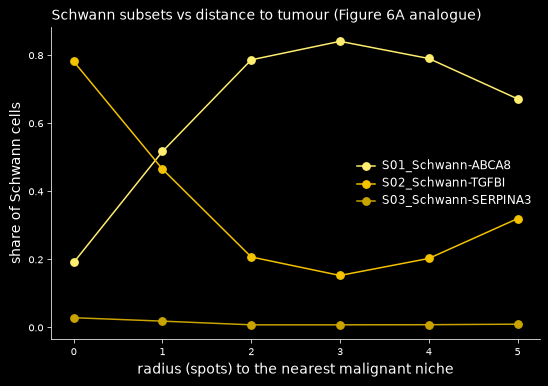

,S01_Schwann-ABCA8,S02_Schwann-TGFBI,S03_Schwann-SERPINA3,n_spots
radius,,,,
0.0,0.191,0.781,0.028,66
1.0,0.517,0.465,0.018,128
2.0,0.786,0.207,0.007,112
3.0,0.840,0.152,0.007,111
4.0,0.790,0.202,0.008,110
5.0,0.671,0.319,0.009,446


In [20]:
df_sd = scp.calc_df_schwann_by_distance(adata_vis, df_abund, df_share, n_rings=5, fname='tsv_schwann_distance', force=force, verbose=verbose)
fig = scp.plot_schwann_distance(df_sd, fname='fig_schwann_distance', force=force, verbose=verbose)
plt.show()
df_sd.round(3)

### 12. Tables

In [21]:
df_region_table = scp.update_region_table_subregions(df_region_table, adata_expr, force=force, verbose=verbose)
cols = ['region_id', 'sub_region_id', 'status', 'subregion_signature_genes', 'not_present_genes', 'enriched_cell_types', 'ref_cell_types']
df_sub_table[[c for c in cols if c in df_sub_table]]

n_subregions unchanged: region table not rewritten
Out[21]: 
    region_id  ...                                                                            ref_cell_types
0         R00  ...                                                                                          
1         R00  ...                      Endocrine (2.53), S01_Schwann-ABCA8 (0.61), S02_Schwann-TGFBI (0.55)
2         R00  ...            F04_hspCAF-HSPA1A (0.88), F02_Progenitor-CAF-DPT (0.81), F07_Fibro-NRP2 (0.44)
3         R00  ...                   D06_Ductal-MYO1A (1.08), Ductal-other (1.03), D08_Ductal-CEACAM5 (0.82)
4         R00  ...           F04_hspCAF-HSPA1A (1.11), F02_Progenitor-CAF-DPT (1.01), F01_myCAF-MMP11 (0.71)
5         R00  ...                     D07_Ductal-MKI67 (0.65), D04_Ductal-GABRP (0.57), Ductal-other (0.56)
6         R00  ...                    F05_dCAF-MKI67 (1.25), F01_myCAF-MMP11 (0.52), D04_Ductal-GABRP (0.45)
7         R00  ...                             F04_hspCAF-HSPA1A (0

,region_id,sub_region_id,status,subregion_signature_genes,not_present_genes,enriched_cell_types,ref_cell_types
0,R00,R00_1,weak; single-section,"IGFBP5, PMEPA1, KRT8, KRT7, S100A11, COL18A1, FLNA, FN1, IGFBP3, MMP11, ACTA2, TAGLN2",,"F01_myCAF-MMP11 (x1.8), D01_Ductal-CFTR (x1.5), Acinar (x0.7)",
1,R00,R00_2,supported; single-section,"CPE, EEF1A2, PAM, GAD2, PARM1, IAPP, SEC11C, CELF3, ELAVL4, STMN2, RBP4, SLC22A17",,"Endocrine (x6.8), Acinar (x3.3), D01_Ductal-CFTR (x0.6)","Endocrine (2.53), S01_Schwann-ABCA8 (0.61), S02_Schwann-TGFBI (0.55)"
2,R00,R00_3,supported; single-section,"PTGDS, LYZ, TXNIP, SELENOP, MFAP4, ABI3BP, MUC5B, MMP2, CCL19, CST3, TGFBR2, DPT",RGS4,"D06_Ductal-MYO1A (x3.2), F04_hspCAF-HSPA1A (x2.7), F02_Progenitor-CAF-DPT (x2.6)","F04_hspCAF-HSPA1A (0.88), F02_Progenitor-CAF-DPT (0.81), F07_Fibro-NRP2 (0.44)"
3,R00,R00_4,supported; single-section,"MUC5B, KLF5, MUC1, MMP1, SLC44A4, GPX2, ADGRF1, TSPAN8, LGALS4, ADAM28, CFH, SLPI",,"D06_Ductal-MYO1A (x2.7), Ductal-other (x2.6), D05_Ductal-PRSS1 (x1.9)","D06_Ductal-MYO1A (1.08), Ductal-other (1.03), D08_Ductal-CEACAM5 (0.82)"
4,R00,R00_5,supported; single-section,"CCN1, DUSP1, VIM, FOS, CCDC80, DCN, ZFP36, MS4A6A, MGP, SFRP2, CEBPD, GPNMB",,"M08_Macro-LYVE1 (x3.3), F02_Progenitor-CAF-DPT (x2.5), F04_hspCAF-HSPA1A (x2.5)","F04_hspCAF-HSPA1A (1.11), F02_Progenitor-CAF-DPT (1.01), F01_myCAF-MMP11 (0.71)"
5,R00,R00_6,supported; single-section; low-depth,"CCN2, S100A4, JUP, KRT23, KRT16, CCN1","TRMT11, UBQLN1, CCT2, LOXL2, NOA1, HS3ST1, RBP4, CARMIL1, NUP214, IGIP, EFNA5, METRN","M08_Macro-LYVE1 (x1.7), D05_Ductal-PRSS1 (x1.6), F02_Progenitor-CAF-DPT (x1.5)","D07_Ductal-MKI67 (0.65), D04_Ductal-GABRP (0.57), Ductal-other (0.56)"
6,R00,R00_7,supported; single-section,"BNIP3L, P4HA1, ADM, VEGFA, DDIT4, SERPINE1, HILPDA, PLOD2, CTSB, LOXL2, ERO1A, ALDOC",KDM5D,"F05_dCAF-MKI67 (x7.6), D04_Ductal-GABRP (x3.5), F01_myCAF-MMP11 (x1.6)","F05_dCAF-MKI67 (1.25), F01_myCAF-MMP11 (0.52), D04_Ductal-GABRP (0.45)"
7,R00,R00_8,supported; single-section,"ERRFI1, SPARCL1, A2M, SLPI, CD74, ANGPTL2, CTSB, CLDN18, C7, MUCL3, RGS1, COL15A1",,"D01_Ductal-CFTR (x2.1), M08_Macro-LYVE1 (x1.8), F02_Progenitor-CAF-DPT (x1.7)","F04_hspCAF-HSPA1A (0.58), Endothelial (0.41), Stellate (0.38)"
8,R01,R01_1,weak; single-section,"MT1X, ELN, IGF1, FNDC1, GAS1, ADAMTS16, MMP23B, SLC12A8, ADAM12, CILP",,"M08_Macro-LYVE1 (x1.3), F02_Progenitor-CAF-DPT (x1.3), F06_Fibro-MALAT1 (x1.2)",
9,R01,R01_2,supported; single-section; high-depth,"OLFM4, MMP7, ELF3, IGFBP5, SPP1, TIMP1, ANXA4, CFTR, ANO1, SPINK1, A2M, PIGR",,"Endothelial (x1.3), F01_myCAF-MMP11 (x1.3), M08_Macro-LYVE1 (x0.9)","D01_Ductal-CFTR (0.91), Ductal-other (0.75), D09_Ductal-CEACAM6 (0.56)"


### Notes for interpretation

- **Nerve calls** are a reproducible proxy of the pathologists' outlines; thresholds are parameters (**nerve_***). Overrides from the H&E go to **pdac/data/pdac_nerve_annotation.tsv**.
- **Invasion** from spot mixtures: a nerve next to dense tumour can be called invaded without perineural invasion; the paper's ENA / PNI / ENI grades need histology.
- **Schwann subsets** rest on 258 reference cells; their spot shares are small and noisy - read trends across rings, not single values.